# Week 2 Day 4 — Agent Swarms

**UnderCover Travel Insurance · Reference notebook**

This notebook builds a **dispatcher–worker swarm**: one LangGraph graph in which a dispatcher node lists the day's claims and fans them out to many claim agents working **in parallel**.

| Part | What it shows |
|---|---|
| 1 | The swarm's plumbing with a no-LLM stand-in: fan-out with `Send`, capping concurrency, retries |
| 2 | The real claim agent in the `work_claim` node, run 5 at once |
| 3 | Scoring a run — quality, cost and time — and sending the scores to Langfuse |
| 4 | 5 agents vs 25: the scoreboard |

Two ideas carry the whole lab:

1. **Orchestration is separate from intelligence.** The graph, the concurrency cap and the retries are plain code with no model in them — Part 1 proves they work with a 1-second stand-in before any tokens are spent.
2. **Parallelism buys time, not accuracy.** More agents finish the queue faster; the decisions are the same quality either way, which Part 4's scoreboard makes visible.

> Markers like **[^1]** point to *Footnotes: recommended changes* at the end. The code is left exactly as it ran; the footnotes say what could be improved.

In [1]:
# Import libraries
# Standard Libraries
import json # For handling JSON data
import operator # For functional-style operations like sorting and comparing
import os # For interacting with the operating system, like file paths
import time # For time-related functions like sleeping or calculating elapsed time
from datetime import datetime # For working with dates and times
from pathlib import Path # For object-oriented filesystems
from typing import Annotated, Literal, TypedDict # For type annotations and structure definitions

# Configuration
from dotenv import load_dotenv # For loading environment variables from a .env file

# Data analysis and visualization
import pandas as pd # For data manipulation and analysis
import plotly.express as px # For interactive data visualization

# LangChain: LLM, tools, and agents
from langchain.agents import create_agent # For creating LangChain agents
from langchain_core.tools import tool # For defining LangChain tools
from langchain_openai import ChatOpenAI # For using OpenAI chat models

# LangGraph: workflow orchestration
from langgraph.graph import END, START, StateGraph # For defining and managing state graphs
from langgraph.types import RetryPolicy, Send # For defining retry policies and sending messages within LangGraph

# Langfuse: tracing and observability
from langfuse import get_client # For obtaining the Langfuse client for tracing and observability
from langfuse.langchain import CallbackHandler # For handling Langfuse callbacks within LangChain

# Local modules
from week2day1_payout import Benefit, Line, Payout, work_out_payout # For handling payout calculations and related data structures

### Connect to OpenRouter and Langfuse

In [2]:
load_dotenv(override=True)
openrouter_api_key = os.getenv('OPENROUTER_API_KEY')
OPENROUTER_BASE_URL = 'https://openrouter.ai/api/v1'
langfuse = get_client()

if openrouter_api_key:
    print(f"OpenRouter API key found and startswith {openrouter_api_key[:5]}")
else: 
    print("OpenRouter API Key not found")

if langfuse.auth_check():
    print('Connected to Langfuse')
else:
    print('No Langfuse key found. Add them to the .env file')


OpenRouter API key found and startswith sk-or
Connected to Langfuse


## Part 1: A dispatcher with no LLM

### The harder claims

Part 1 builds and tests the swarm's **orchestration** with no LLM in it at all. The data is the 25 *harder* claims from `data/evals/harder`: `claims` to work, `labels` with the handlers' decisions (the ground truth for scoring), and `policies` for the agent's prompt. Everything is keyed by id, so a worker can look up all it needs from just a `claim_id`.

In [3]:
HARDER = Path("../../../data/evals/harder")

def load(name):
    """ Read one of the JSON files of the harder claims. """
    return json.loads((HARDER / name).read_text(encoding='utf-8'))

claims = {claim['claim_id']: claim for claim in load('claims.json')}
labels = {decision['claim_id']: decision for decision in load('decisions.json')}
policies = {policy['policy_id']: policy for policy in load('policies.json')}
policy_wording = Path('../../../data/policy_wording.md').read_text(encoding='utf-8')
print(f"{len(claims)} claims, {len(labels)} labels, {len(policies)} policies")

25 claims, 25 labels, 25 policies


### The dispatcher's state

`Dispatch` is the graph's shared state. The key detail is the **reducer**: `results` is `Annotated[list, operator.add]`, so when many parallel branches each return `{'results': [one_result]}`, LangGraph *concatenates* them instead of letting one overwrite another. Without the reducer, parallel writes to the same key would be an error. [^1]

In [4]:
class Dispatch(TypedDict): # The structure for the dispatcher's state in one run
    """ What the dispatcher keeps for one run."""
    claims: list['str']
    results: Annotated[list, operator.add]


### Listing the claims and fanning out

`fan_out` is the heart of the swarm. A conditional edge that returns a list of `Send` objects tells LangGraph to run the target node **once per `Send`, in parallel** — one `work_claim` per claim, each receiving just its claim id as input. This is LangGraph's map-reduce pattern: `Send` maps the work out, and the `operator.add` reducer gathers the results back.

In [5]:
def list_claims(state: Dispatch): # List all claim ids in the state
    """ The claims to work in this run"""
    return {'claims': list(claims)}

def fan_out(state: Dispatch): # Fan out the claims to the results
    """ Send each claim to a claim agent."""
    return [Send('work_claim', claim_id) for claim_id in state['claims']]


### A stand-in for the claim agent

The stand-in pretends to work a claim for one second and returns the same *shape* of result the real agent will: a one-entry list, timestamped `started` and `finished`. Rehearsing with it is free and deterministic — 25 claims × 1 second, divided by however many run at once.

In [6]:
def stand_in(claim_id): 
    """Pretend to work a claim for one second."""
    started = datetime.now()
    time.sleep(1)
    return {'results': [
        {
            'claim_id': claim_id,
            'started': started,
            'finished': datetime.now()
        }]}

### Building the graph

The graph is `START → list_claims → (fan out) → work_claim → END`. `work_claim` appears **once** in the graph but runs many times per invoke — the dashed conditional edge in the drawing is where the fan-out happens. [^2]

In [7]:
builder = StateGraph(Dispatch) # Initialize the state graph with the Dispatch mechanism
builder.add_node('list_claims', list_claims) # Add the 'list_claims' node to the state graph
builder.add_node('work_claim', stand_in) # Add the 'work_claims' node to the state graph
builder.add_edge(START, 'list_claims') # Add an edge from the START node to the 'list_claims' node
builder.add_conditional_edges('list_claims', fan_out, ['work_claim']) #  Add conditional edges from 'list_claims' to 'fan_out' for 'work_claims' 
builder.add_edge('work_claim', END) # Add an edge from the 'work_claims' node to the END node
dispatcher = builder.compile() # Compile the state graph into a dispatcher

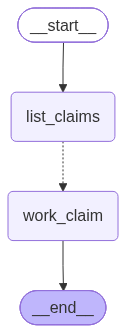

In [8]:
dispatcher

### Capping the swarm

`max_concurrency` in the invoke **config** caps how many `work_claim` branches run at once — the graph itself doesn't change. With the 1-second stand-in the arithmetic is visible: 1 at once ≈ 25s, 5 at once ≈ 5s, 25 at once ≈ 1s. In Part 2 the same knob throttles real LLM calls, which is how the swarm respects rate limits.

In [9]:
result = dispatcher.invoke({}, {'max_concurrency': 1}) # Invoke the dispatcher with a maximum concurrency of 1 agent
table = pd.DataFrame(result['results']) # Convert the results into a pandas DataFrame for easier analysis
seconds = (table['finished'].max() - table['started'].min()).total_seconds() # Calculate the total time taken for all claims to be processed
print(f"1 agent at once: {len(table)} claims in {seconds:.1f} seconds") # Print the number of claims processed and the total time taken

1 agent at once: 25 claims in 25.1 seconds


In [10]:
result = dispatcher.invoke({}, {'max_concurrency': 5}) # Invoke the dispatcher with a maximum concurrency of 5 agents
table = pd.DataFrame(result['results']) # Convert the results into a pandas DataFrame for easier analysis
seconds = (table['finished'].max() - table['started'].min()).total_seconds() # Calculate the total time taken for all claims to be processed
print(f"5 agents at once: {len(table)} claims in {seconds:.1f} seconds") # Print the number of claims processed and the total time taken

5 agents at once: 25 claims in 5.0 seconds


In [11]:
result = dispatcher.invoke({}, {'max_concurrency': 25}) # Invoke the dispatcher with a maximum concurrency of 25 agents
table = pd.DataFrame(result['results']) # Convert the results into a pandas DataFrame for easier analysis
seconds = (table['finished'].max() - table['started'].min()).total_seconds() # Calculate the total time taken for all claims to be processed
print(f"25 agents at once: {len(table)} claims in {seconds:.1f} seconds") # Print the number of claims processed and the total time taken


25 agents at once: 25 claims in 1.0 seconds


In [12]:
def show_timeline(results, title): # Show a timeline of claims for visualization purposes
    """ Draw each claim as a bar from when it started to  to when it ended"""
    fig = px.timeline(pd.DataFrame(results),
                      x_start='started', 
                      x_end='finished', 
                      y='claim_id',
                      title=title)
    fig.update_yaxes(autorange='reversed')
    fig.show()

result = dispatcher.invoke({}, {'max_concurrency': 5})
show_timeline(result['results'], 'The stand-in, 5 at once')

### Retries

`flaky_stand_in` fails the **first** attempt on CLM-1207 with a fake `429 Too Many Requests` — exactly the error a busy swarm provokes from a rate-limited API. `retry_policy=RetryPolicy(max_attempts=3)` on the node makes LangGraph wait and rerun *just that branch*; the other 24 claims are untouched. On the timeline, CLM-1207 finishes late, after its retry.

In [13]:
tries = {}
def flaky_stand_in(claim_id):
    """ the stand-in, failing the first time it works CLM-1207."""
    tries[claim_id] = tries.get(claim_id, 0) + 1
    if claim_id == 'CLM-1207' and tries[claim_id] == 1:
        raise Exception('429 Too Many Requests')
    return stand_in(claim_id)

In [14]:
builder = StateGraph(Dispatch) # Initialize the state graph with the Dispatch class
builder.add_node('list_claims', list_claims) # Add the 'list_claims' node to the state graph
builder.add_node('work_claim', flaky_stand_in, retry_policy=RetryPolicy(max_attempts=3))
builder.add_edge(START, 'list_claims') # Connect the start node to the 'list_claims' node 
builder.add_conditional_edges('list_claims',fan_out, ['work_claim']) # Add conditional edges from 'list_claims' to 'work_claims' based on the fan_out function 
builder.add_edge('work_claim', END) # Connect the 'work_claims' node to the end node 
flaky_dispatcher = builder.compile() # Compile the state graph into a dispatcher

result = flaky_dispatcher.invoke({}, {'max_concurrency': 25})
print(f"{len(result['results'])} claims done. CLM-1207 took {tries['CLM-1207']} tries.")
show_timeline(result['results'], "The flaky stand-in , 25 at once")


25 claims done. CLM-1207 took 2 tries.


**Part 1 summary.** The swarm's machinery is proven before a single token is spent: `Send` fans 25 claims out to parallel workers, the `operator.add` reducer gathers their results, `max_concurrency` caps the parallelism, and `RetryPolicy` absorbs transient failures. All that's left is to swap the stand-in for a real agent.

## Part 2: A swarm of claims agents

Part 2 replaces the stand-in with a real claim agent — Day 1's agent, unchanged in spirit: the instructions and the policy wording as the system prompt, the claim and the customer's policy record as the user message, and two tools, `record_decision` and `calculate_payout`. [^7]

In [15]:
INSTRUCTIONS = """ You are a claims handler at UnderCover Travel Insurance. Decide the claim
you are given, using the policy wording below and the customer's policy record.


choose one decision: 
- approve: the wording covers the claim and the required documents are attached. Work out the payout using section 10.
- decline: the wording does not cover the claim.
- refer: a colleague needs to look at it, because a required document is missing, or the story and the documents 
disagree, or the wording does not settle the question.

Use your tools to record your decision.
Use the payout tool to work out the payout on an approved claim, and record the payout it returns.
"""

def make_user_prompt(claim):
    """ The customer's policy record and the claim, as JSON."""
    policy= policies[claim['policy_id']]
    return f"""# Policy record 
    {json.dumps(policy, indent=2)}
# Claim

{json.dumps(claim, indent=2)}"""


Both tools use `@tool(parse_docstring=True)`, so the docstring and each `Args:` line become the tool's schema — it's what the model reads when deciding how to call the tool. [^3]

Two guardrails in `record_decision` matter in a swarm: a decision **can't be changed once recorded**, which makes retries safe (a worker rerun after a timeout can't overwrite a decision that already landed), and an approval needs a payout above zero. [^4]

In [16]:
recorded = {} # Stores the decisions and payout for each claim

@tool(parse_docstring=True) # Records the decision and payout for a claim
def record_decision(claim_id: str, rationale: str, decision: Literal['approve', 'decline', 'refer'], payout: float) -> str: # Records the decision and payout for a claim
    """ Record the decision on a claim in the claims system.

    Args:
        claim_id: The claim's id.
        rationale: 2-3 sentences to explain the decision along with the relevant section of the policy.
        decision: The decision on the claim..
        payout: The amount to pay in US dollars, or 0 for a decline or a referral.
""" 
    if claim_id in recorded:
        return f"A decision is already recorded on {claim_id}, and decisions are final."
    if decision == 'approve' and payout <=0: 
        return "An approval needs a payout above zero."
    recorded[claim_id]= {
        'decision': decision,
        'payout': payout,
        'rationale': rationale
    }
    return f"Recorded {decision} on {claim_id}"


In [17]:
@tool(parse_docstring=True)
def calculate_payout(policy_id: str, benefit: Benefit, lines: list[Line], paid_by_others: float=0.0) -> Payout: # Calculate the payout for a given policy, benefit, and lines, considering any amounts paid by others.
    """ Work out the payout on an approved claim with UnderCover's payout rules. 
    
    Args: 
        policy_id: The customer's policy id.
        benefit: The benefit the claim is paid under.
        lines: The covered items and expenses, one for each line of the claim, with any excluded ones left out. A pair oa set counts as one item.
        paid_by_others: Anything a carrier, hotel or other party has paid or refunded for the same loss.

    Returns:
        The calculation, the payout and whether it needs sign-off
    """
    return work_out_payout(policies[policy_id], benefit, lines, paid_by_others)


In [18]:
luna = ChatOpenAI(model='openai/gpt-6-luna',
                  base_url=OPENROUTER_BASE_URL,
                  api_key=openrouter_api_key,
                  reasoning_effort='low',
                  timeout=120,
                  max_retries=5)
payout_agent = create_agent(model=luna,
                            tools=[record_decision,
                                   calculate_payout],
                            system_prompt=f'{INSTRUCTIONS}\n{policy_wording}\n')

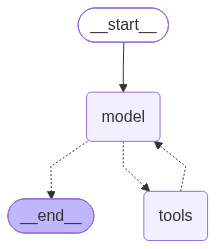

In [19]:
payout_agent

### The work_claim node

`work_claim` keeps the stand-in's contract: take a claim id, return `{'results': [one row]}`. It invokes the agent, then reads the decision out of `recorded` — falling back to a `refer` with *"Nothing recorded"* if the agent never called its tool, so a silent failure becomes a referral instead of a crash. `cost` sums OpenRouter's per-call cost across the run's AI messages.

In [20]:
def work_claim(claim_id): # Process a claim using the payout agent.
    """ Run the claim agent on one claim and return its result."""
    started = datetime.now()
    result = payout_agent.invoke({
        'messages': [
            {
                'role': 'user',
                'content': make_user_prompt(claims[claim_id])
            }
        ]
    })
    answer = recorded.get(claim_id, 
                          {'decision': 'refer',
                           'payout': 0.0,
                           'rationale': 'Nothing recorded'})
    cost = sum(message.response_metadata['token_usage']['cost'] for message in result['messages'] if message.type == 'ai')
    print(f"{claim_id}: {answer['decision']} ${answer['payout']:.2f}")
    return {'results': [{'claim_id': claim_id, **answer, 'cost': cost, 'started': started, 'finished': datetime.now()}]}
          


In [21]:
work_claim('CLM-1203')

CLM-1203: approve $2910.44


{'results': [{'claim_id': 'CLM-1203',
   'decision': 'approve',
   'payout': 2910.44,
   'rationale': "The theft occurred during the covered trip, and the police report documents the stolen belongings; the insurer's payment is documented and deducted. Section 5 covers theft reported to police with a report, and section 10 applies item limits, the $100 total cash cap and other-party payments; the payout tool returns $2,910.44. The calculator flags this payout as needing sign-off.",
   'cost': 0.00040159500000000003,
   'started': datetime.datetime(2026, 11, 6, 6, 36, 21, 955676),
   'finished': datetime.datetime(2026, 11, 6, 6, 36, 27, 578654)}]}

### The swarm

The same graph as Part 1 — only the worker function changed. The retry policy now guards against real failures: timeouts and rate limits from the model API. The cell after the drawing lets you set `TINY = True` to work only the claims flagged `tiny`, for a quicker, cheaper run.

In [22]:
builder = StateGraph(Dispatch) # Initialize the state graph with the Dispatch agent
builder.add_node('list_claims', list_claims) # Add the list_claims node to the state graph
builder.add_node('work_claim', work_claim, retry_policy=RetryPolicy(max_attempts=3)) # Add the work_claim node to the state graph
builder.add_edge(START, 'list_claims') # Add an edge from the START node to the list_claims node
builder.add_conditional_edges('list_claims', fan_out, ['work_claim']) # Add conditional edges from list_claims to work_claim based on the fan_out function
builder.add_edge('work_claim', END) # Add an edge from the work_claim node to the END node
dispatcher = builder.compile() # Compile the state graph into a dispatcher

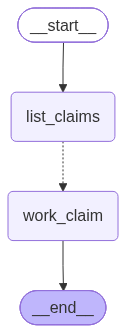

In [23]:
dispatcher

In [24]:
TINY = False

if TINY:
    claims = {claim_id: claim for claim_id, claim in claims.items() if labels[claim_id]['tiny']}

print(f"The swarm works {len(claims)} claims")

The swarm works 25 claims


### Five claims agents at once

Langfuse's `CallbackHandler` goes in the invoke config, and LangGraph hands the config on to **every node** — so every agent's model and tool calls land in one trace for the whole run, named by `run_name`. `recorded.clear()` resets the decisions so a rerun starts clean.

In [25]:
langfuse_handler = CallbackHandler()

recorded.clear()
result = dispatcher.invoke({}, {'max_concurrency': 5, 
                                'callbacks': [langfuse_handler],
                                'run_name': 'Swarm of 5'})
swarm_of_5 = result['results']

CLM-1205: approve $1021.14
CLM-1201: approve $563.30
CLM-1202: approve $2048.44
CLM-1206: approve $1450.01
CLM-1203: approve $2310.44
CLM-1204: approve $4787.25
CLM-1207: approve $1306.72
CLM-1210: decline $0.00
CLM-1212: refer $0.00
CLM-1208: approve $3668.80
CLM-1211: refer $0.00
CLM-1213: decline $0.00
CLM-1214: approve $622.60
CLM-1209: approve $4180.15
CLM-1216: approve $1677.90
CLM-1215: approve $1415.78
CLM-1219: decline $0.00
CLM-1220: decline $0.00
CLM-1221: decline $0.00
CLM-1217: approve $1335.90
CLM-1222: refer $0.00
CLM-1225: refer $0.00
CLM-1224: refer $0.00
CLM-1223: refer $0.00
CLM-1218: decline $0.00


In [26]:
show_timeline(swarm_of_5, 'The claim agents, 5 at once')

**Part 2 summary.** The swarm is live: the dispatcher fans the 25 harder claims out to real claim agents, five at a time, each deciding and recording a claim with the same tools as Day 1. The timeline shows a new claim starting the moment one of the five finishes, and the whole run sits in a single Langfuse trace.

## Part 3: Scoring the run

A faster swarm is worthless if it decides worse, so each run is scored on three axes:

- **Quality** — `decision_accuracy` (decision matches the handler's), `accuracy` (decision *and* payout within a dollar), `cost_of_mistakes` (a wrongful decline costed at \$1,500, a needless referral at \$50), and `straight_through` (the share decided without a human).
- **Cost** — `llm_cost`, what the run's model calls cost.
- **Time** — `seconds` for the whole run, plus the slowest claim and the average per claim.

`score_table` builds one row per claim, the agent's answer beside the handler's; `run_scores` rolls a table up into one summary.

In [27]:
WRONGFUL_DECLINE = 1500
NEEDLESS_REFERRAL = 50

def is_right(answer, expected): # Check if the answer matches the expected value 
    """ True when the decision matches the handler's and the payout is within a dollar."""
    return answer['decision'] == expected['decision'] and abs(answer['payout'] - expected['payout']) <= 1 

def mistake_cost(answer, expected): #  Calculate the cost of a mistake
    """ What the agent's answer costs UnderCover, against the handler's decision."""
    if answer['decision'] == expected['decision']:
        return abs(answer['payout'] - expected['payout']) if answer['decision'] == 'approve' else 0
    if answer['decision'] == 'decline':
        return WRONGFUL_DECLINE
    if answer['decision'] == 'approve':
        return answer['payout']
    return NEEDLESS_REFERRAL
 

In [28]:
def score_table(results): # Returns a table with one row for each claim, showing the agent's answer, the handler's answer, and the scores.
    """ One Row for each claim in a run:The agent's answer beside the handler's , with the scores."""
    rows = []
    for answer in results:
        expected = labels[answer['claim_id']]
        rows.append({
            'claim_id': answer['claim_id'],
            'handler': expected['decision'],
            'agent': answer['decision'],
            'handler_payout': expected['payout'],
            'agent_payout': answer['payout'],
            'right': is_right(answer, expected),
            'mistake_cost': mistake_cost(answer, expected),
            'llm_cost': answer['cost'],
            'started': answer['started'],
            'finished': answer['finished'],
            'seconds': (answer['finished'] - answer['started']).total_seconds(),
            'rationale': answer['rationale']
        })
    return pd.DataFrame(rows).sort_values('claim_id')

def run_scores(table): # Returns a summary of the scores for a run.
    """ The scores for a whole run: quality, cost, and time. """
    return {
        'decision_accuracy': (table['agent'] == table['handler']).mean(),
        'accuracy': table['right'].mean(),
        'cost_of_mistakes': table['mistake_cost'].sum(),
        'straight_through': (table['agent'] != 'refer').mean(),
        'llm_cost': table['llm_cost'].sum(),
        'seconds': (table['finished'].max() - table['started'].min()).total_seconds(),
        'slowest_claim': table['seconds'].max(),
        'seconds_per_claim': table['seconds'].mean()
    }


In [29]:
table_5 = score_table(swarm_of_5)
scores_5 = run_scores(table_5)

pd.Series(scores_5).round(3)

decision_accuracy       0.960
accuracy                0.880
cost_of_mistakes     2110.020
straight_through        0.760
llm_cost                0.009
seconds                38.565
slowest_claim          17.929
seconds_per_claim       6.400
dtype: float64

In [30]:
table_5[~table_5['right']]

,claim_id,handler,agent,handler_payout,agent_payout,right,mistake_cost,llm_cost,started,finished,seconds,rationale
0,CLM-1201,approve,approve,553.28,563.30,False,10.02,0.000371,2026-11-06 06:36:27.691271,2026-11-06 06:36:33.581407,5.890136,The carrier report confirms the checked suitca...
2,CLM-1203,approve,approve,2910.44,2310.44,False,600.00,0.000405,2026-11-06 06:36:27.697200,2026-11-06 06:36:39.168500,11.471300,"The theft occurred during the covered trip, an..."
17,CLM-1218,approve,decline,4427.95,0.00,False,1500.00,0.001099,2026-11-06 06:36:48.327691,2026-11-06 06:37:06.256196,17.928505,The trip was canceled because Hurricane Ines c...


### Scores in Langfuse

`send_scores` attaches each measure to the run's trace in Langfuse, so runs can be compared in the UI. `last_trace_id` is the trace the handler saw most recently — the *Swarm of 5* run, provided the cells ran in order. [^5]

In [31]:
def send_scores(trace_id, scores): # Send the scores for a given trace ID
    """ Add a run's scores to its trace in Langfuse. """
    for name, value in scores.items():
        langfuse.create_score(trace_id=trace_id,
                              name=name,
                              value=float(value))
send_scores(langfuse_handler.last_trace_id, scores_5)

**Part 3 summary.** The run now has numbers: quality measured against the handlers' decisions, the dollar cost of mistakes and of the LLM, and wall-clock time — kept locally in a DataFrame and attached to the run's trace in Langfuse.

## Part 4: 5 agents or 25

The same swarm again with `max_concurrency: 25`, scored the same way. The scoreboard puts both runs side by side: quality and LLM cost stay essentially the same — an agent doesn't know how many colleagues it has — while the wall-clock time falls with more agents. Parallelism buys **time**; the ceiling is the provider's rate limits, which is what the retry policy is for.

In [32]:
recorded.clear()
result = dispatcher.invoke({}, {'max_concurrency': 25,
                                'callbacks': [langfuse_handler],
                                'run_name': 'Swarm of 25'})
swarm_of_25 = result['results']

table_25 = score_table(swarm_of_25)
scores_25 = run_scores(table_25)
send_scores(langfuse_handler.last_trace_id, scores_25)

CLM-1210: decline $0.00
CLM-1212: refer $0.00
CLM-1213: decline $0.00
CLM-1222: refer $0.00
CLM-1220: decline $0.00
CLM-1221: decline $0.00
CLM-1225: refer $0.00
CLM-1214: approve $622.60
CLM-1224: refer $0.00
CLM-1206: approve $1450.01
CLM-1211: refer $0.00
CLM-1201: approve $553.28
CLM-1208: approve $3668.80
CLM-1207: approve $1306.72
CLM-1223: refer $0.00
CLM-1205: approve $1021.14
CLM-1215: approve $1415.78
CLM-1203: approve $2910.44
CLM-1216: approve $1228.90
CLM-1219: decline $0.00
CLM-1209: approve $4180.15
CLM-1202: approve $2048.44
CLM-1217: approve $1335.90
CLM-1204: approve $4787.25
CLM-1218: decline $0.00


In [33]:
show_timeline(swarm_of_25, 
              'The claim agents, 25 at once')

### The scoreboard

In [34]:
pd.DataFrame([scores_5, scores_25],
             index=["5 at once",
                    '25 at once']).round(3)

,decision_accuracy,accuracy,cost_of_mistakes,straight_through,llm_cost,seconds,slowest_claim,seconds_per_claim
5 at once,0.96,0.88,2110.02,0.76,0.009,38.565,17.929,6.400
25 at once,0.96,0.92,1949.00,0.76,0.009,22.401,22.341,6.863


## Conclusion

This notebook turned one claim agent into a swarm without changing the agent itself:

1. **The dispatcher–worker pattern.** One LangGraph graph: a dispatcher node, a single worker node fanned out with `Send`, results gathered by an `operator.add` reducer.
2. **Rehearse the plumbing first.** Part 1 proved fan-out, concurrency caps and retries with a 1-second stand-in — free, fast and deterministic.
3. **Operational knobs live in config, not code.** `max_concurrency`, callbacks and the run name all go in the invoke config, so the same compiled graph runs as 1, 5 or 25 agents.
4. **Idempotency makes retries safe.** Decisions are final in `record_decision`, so a retried worker can't record twice.
5. **Score before you scale.** The scoreboard shows the bigger swarm finishing far sooner at the same quality and LLM cost — evidence, not hope.

Next, on Week 2 Day 5, the agent's configuration moves into versions and an improver agent starts proposing better ones.

## Footnotes: recommended changes

The code above is left exactly as it ran. These are the changes worth making, in page order.

**[^1] `Dispatch.claims` annotation.** `claims: list['str']` quotes the type, making it a forward reference to the *string* `'str'` rather than the type `str`. It runs fine — LangGraph doesn't enforce it — but it should read `claims: list[str]`.

**[^2] The graph is built three times.** The stand-in, flaky stand-in and real swarm cells repeat the same five `builder` lines, differing only in the worker function and retry policy. A helper such as `build_dispatcher(worker, retry=None)` would keep the wiring in one place.

**[^3] Tool docstrings are part of the prompt.** With `parse_docstring=True`, docstring typos travel to the model: `record_decision` has *"The decision on the claim.."* (double period) and `calculate_payout` has *"A pair oa set"* (should be *"a pair or a set"*). Harmless here, but a reference prompt should be clean.

**[^4] `recorded` is shared mutable state.** Every parallel worker writes to one module-level dict. It's safe here — each worker writes only its own `claim_id`, and decisions are final — but in production this belongs in the graph's state or the claims database, not a global.

**[^5] `last_trace_id` depends on cell order.** `send_scores(langfuse_handler.last_trace_id, ...)` scores whichever trace the handler saw last; run cells out of order and the scores land on the wrong trace. Safer: capture the trace id right after each `invoke`, and call `langfuse.flush()` after the last send.

**[^6] Trailing empty cell.** The last code cell is empty and can be deleted.

**[^7] `INSTRUCTIONS` polish.** Minor wording: *"choose one decision"* should be capitalised, and the stray blank line after the first paragraph can go. The model forgives this; it's just tidiness in a prompt you'll reuse.